In [1]:
%load_ext autoreload
%autoreload 2

# dataIO: Positron focused (511 keV)
***

## Setup

### Imports

In [2]:
# Setting the root path for the imports
from pathlib import Path
import sys
working_dir=Path.cwd()
repo_root = (
    working_dir.parent if working_dir.name =='notebooks' else working_dir)
if repo_root not in sys.path: sys.path.insert(0,repo_root)

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import cosipy as cp
from cosipy.util import fetch_wasabi_file
from cosipy.response import FullDetectorResponse
from cosipy.pipeline.src.preprocessing import write_yaml

from scoords import SpacecraftFrame

from astropy.io import fits
import astropy.units as u
from astropy.coordinates import SkyCoord


import h5py


%matplotlib inline


### Paths to data files

In [ ]:
# Input directories
data_dir = repo_root / "data" / "inputs"
data_dir.mkdir(parents=True, exist_ok=True)

# Orientation data 
orientation_filename= "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits"
data_ori_path = data_dir / orientation_filename


# Mock dataset: 14 weeks
weekly_files = {
    i: f"dc4_mock_dataset_week_{i}_unbinned_data_filtered_with_SAAcut.fits.gz"
    for i in range(1, 15)
}

weekly_paths = {
    week: data_dir / filename
    for week, filename in weekly_files.items()
}

# Response data
responses = ["Response511.o4.e509_513.s20881894470591.m2555.filtered.nonsparse.binnedimaging.imagingresponse.h5"]

data_response511_path = data_dir / responses[0]

# extended response data 
extended_responses_gz = ["extended_source_response_511_merged.h5.gz"]

extended_responses = ["extended_source_response_511_merged.h5"]

data_ext_response511_path = data_dir/extended_responses[0]


# Output directory
data_dir_out = repo_root / "data" / "outputs"
plot_dir_out = repo_root / "plot_outputs"

# yaml files

config_dir = repo_root / "data" / "config"
config_511_path = config_dir / "dataio_511.yaml"


### Download Data
Skip this part if data already exist in the repository

In [5]:
def download_if_missing(remote_path, data_dir):
    filename = Path(remote_path).name
    local_file = data_dir / filename
   
    if local_file.exists():
        print(f"skipping {filename}: already exists")
        return

    fetch_wasabi_file(remote_path, output = str(data_dir))


In [ ]:
# download the data we will need for this notebook.


# Mock dataset: 14 weeks
for week, filename in weekly_files.items():
    download_if_missing(f"COSI-SMEX/DC4/Data/Mock_Dataset/{filename}", data_dir)

# Orientation data
download_if_missing(f"COSI-SMEX/DC4/Data/Orientation/{orientation_filename}",  data_dir)

# Responses
for filename in responses:
    
    download_if_missing(f"COSI-SMEX/DC4/Data/Responses/{filename}", data_dir)

# Extended responses
for filename in extended_responses_gz:
    
    download_if_missing(f"COSI-SMEX/DC3/Data/Responses/extended_source_response/{filename}", data_dir)


### Load and inspect response511
We need this step only if `.yaml` file is not created yet. Otherwise we can skip

In [7]:
with fits.open(weekly_paths[1]) as hdul:
    tmin = hdul[1].data["TimeTags"].min()

with fits.open(weekly_paths[14]) as hdul:
    tmax = hdul[1].data["TimeTags"].max()

In [8]:
config_dir.mkdir(parents=True, exist_ok=True)
dt = 3600.0
write_yaml(
    udata_path=str(weekly_paths[1]),
    ori_path=str(data_ori_path),
    resp_path=str(data_response511_path),
    dt=dt,
    tmin=float(tmin),
    tmax=float(tmax),
    bin_yaml_path=str(config_511_path),
)

()

***
## Binning the data

In [10]:
analysis511 = {}

data_dir_out.mkdir(parents=True, exist_ok=True)

for week, input_path in weekly_paths.items():
    output_prefix = data_dir_out / f"dc4_week_{week}_511_binned"
    output_path = output_prefix.with_suffix(".hdf5")

    analysis511[week] = cp.BinnedData(config_511_path)

    if not output_path.exists():
        analysis511[week].get_binned_data(
            unbinned_data=str(input_path),
            output_name=str(output_prefix),
        )

    analysis511[week].load_binned_data_from_hdf5(
        binned_data=str(output_path)
    )

    analysis511[week].get_binning_info()

    

### Binned data exploration

In [ ]:
# Exploring the data shape

print("511 keV - 5th week - shape", analysis511[5].binned_data.shape)
print()
print("---------------------------------------------------------------------------------------")
print()
# Inspecting eges, cemnters, etc
print("511 keV - 5th week - energy edges", analysis511[5].energy_bin_edges)
print()
print("---------------------------------------------------------------------------------------")
print()
print("511 keV - 5th week - energy centers",analysis511[5].energy_bin_centers)


In [ ]:
print(analysis511[5].binned_data.shape)
print(len(analysis511[5].time_bin_centers))


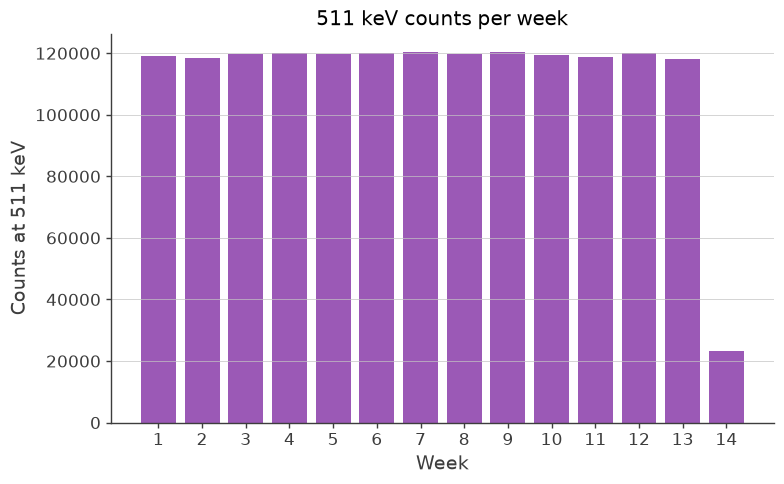

In [14]:
# Plotting the counts per week
weeks = list(analysis511)
counts = [
    np.asarray(analysis511[week].binned_data.todense().contents).sum()
    for week in weeks
]

plt.figure(figsize=(8, 5))
plt.bar(weeks, counts)
plt.xlabel("Week")
plt.ylabel("Counts at 511 keV")
plt.title("511 keV counts per week")
plt.xticks(weeks)
plt.grid(axis="y")


plt.tight_layout()
plt.show()

***
## Detector response exploration

### Response

In [ ]:
# Open and inspect the detector response
with cp.response.FullDetectorResponse.open(data_response511_path) as response:
    print("Response 511 keV axes:", response.axes.labels)
    print('----------------------------------------------------------------')
    print('------------------------- Description --------------------------')
    print('----------------------------------------------------------------')
    print(repr(response))
    print('----------------------------------------------------------------')
    print('')
    print(f"NSIDE = {response.nside}")
    print(f"SCHEME = {response.scheme}")
    print(f"NPIX = {response.npix}")
    print(f"Pixel size = {np.sqrt(response.pixarea()).to(u.deg):.2f}")
    print('')
    print('----------------------------------------------------------------')


In [ ]:
with cp.response.FullDetectorResponse.open(data_response511_path) as response:
    drm511 = response.get_interp_response(
        SkyCoord(
            lon=0 * u.deg,
            lat=0 * u.deg,
            frame=SpacecraftFrame(),
        )
    )

drm511.get_spectral_response().plot()


In [ ]:
# The effective area can also be evaluated at a specific energy of interest:
# drm511.get_effective_area(energy_of_interest)
ax,plot = drm511.get_effective_area().plot();

ax.set_ylabel(f'Aeff [{drm511.unit}]');
